# 🛡️ Sesión 11 — Deducible, coaseguro y franquicia: cómo cambian la prima
## Matemáticas Actuariales para Seguro de Daños, Fianzas y Reaseguro · UNAM

---

**Tema 2.7 · Elementos condicionados para el cálculo de primas** · **Herramienta:** Python

---

> **Objetivo:** entender que el deducible, el coaseguro, el límite (suma asegurada) y la franquicia
> **no son un descuento a ojo**: son **transformaciones de la severidad** $X$. Al cambiar lo que la
> aseguradora paga por siniestro, cambia $E[\text{pago}]$ y con ello la **prima pura**. Veremos cuánto
> baja la prima, por qué no es lineal, y de dónde salen las **tablas de factores** de las aseguradoras.
>
> 🟢 Las celdas normales las corremos juntos. **✏️ Las de Ejercicio las completas tú.**

## Contenido
1. [Entorno](#1)
2. [La cartera: severidad ground-up y prima base](#2)
3. [Deducible](#3)
4. [Costo por siniestro vs. costo por pago](#4)
5. [Coaseguro y límite (suma asegurada)](#5)
6. [Franquicia](#6)
7. [Casos analíticos: exponencial y lognormal](#7)
8. [La curva prima vs. deducible y las tablas de factores](#8)
9. [El entregable: `prima_ajustada(...)`](#9)
10. [Cierre](#10)

---

---
<a id='1'></a>
## 1. Entorno

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
np.set_printoptions(suppress=True)
plt.rcParams["figure.figsize"] = (7, 4)
print("✓ listo")

✓ listo


---
<a id='2'></a>
## 2. La cartera: severidad ground-up y prima base

Trabajamos sobre la cartera del ramo. Lo importante: `monto_promedio_siniestro` es la severidad
**ground-up** (el costo del siniestro **antes** de aplicar cualquier condición de la póliza). Esa es la
variable $X$ que vamos a transformar.

> 🔁 **Para tu equipo:** cambia el nombre del archivo por el de **tu** cartera. Todo lo demás corre igual.

In [2]:
# ─── Cargar la cartera y extraer la severidad ground-up ────────────────────
# 📁 RUTA DE LOS DATOS — cambia SOLO esta línea por la de tu cartera.
#    (si el archivo está en otra carpeta, pon la ruta completa, p. ej.
#     r"C:/Users/tu_usuario/Documents/MASDFR/mi_cartera.parquet")
RUTA_DATOS = "cartera_ejemplo_autos.parquet"

df = pd.read_parquet(RUTA_DATOS)

X = df["monto_promedio_siniestro"].dropna().values      # severidad ground-up por siniestro
freq = df["num_siniestros"].sum() / df["exposicion"].sum()   # frecuencia (siniestros por año-póliza)

EX = X.mean()
prima_pura_base = freq * EX

print(f"Siniestros en la muestra : {len(X):,}")
print(f"Severidad media E[X]     : ${EX:,.2f}")
print(f"Frecuencia               : {freq:.4f}")
print(f"Prima pura ground-up     : ${prima_pura_base:,.2f}   (= frecuencia × E[X], sin condiciones)")

Siniestros en la muestra : 6,732
Severidad media E[X]     : $52,462.53
Frecuencia               : 0.3583
Prima pura ground-up     : $18,797.89   (= frecuencia × E[X], sin condiciones)


---
<a id='3'></a>
## 3. Deducible

El **deducible** $d$ es un monto que el asegurado absorbe en **cada** siniestro; la aseguradora paga el
exceso:

$$Y = \max(X - d,\ 0) = (X-d)_+$$

Su valor esperado —el costo esperado por siniestro para la aseguradora— es

$$E[(X-d)_+] = \int_d^\infty (x-d)\,f(x)\,dx = \int_d^\infty S(x)\,dx$$

(la segunda forma, el área bajo la curva de supervivencia, es útil y la retomamos en los casos analíticos).
La **prima pura con deducible** es $\text{frecuencia}\times E[(X-d)_+]$.

> **¿Qué es el "factor"?** Es la **fracción del costo original que queda** después del deducible:
> $$\text{factor}(d)=\frac{E[(X-d)_+]}{E[X]}=\frac{\text{lo que paga CON deducible}}{\text{lo que pagaría SIN deducible}}$$
> En $d=0$ vale 1 (no se recorta nada). Si vale 0.66, la aseguradora espera pagar el **66%** de lo que
> pagaba sin deducible → la prima es el **66% de la base**. Por eso el factor es el *multiplicador* de la prima.

In [3]:
# ─── El pago bajo deducible, paso a paso ───────────────────────────────────
def E_deducible(X, d):
    """E[(X-d)+] : lo que la aseguradora paga en promedio por siniestro, con deducible d."""
    return np.maximum(X - d, 0).mean()

print(f"Costo promedio SIN deducible:  E[X] = ${EX:,.0f}  (el 100% del siniestro medio)")
print()
for d in [0, 10_000, 20_000, 30_000]:
    e      = E_deducible(X, d)        # lo que paga la aseguradora con deducible d
    factor = e / EX                   # fracción del costo original que QUEDA = parte / total
    prima  = freq * e                 # prima pura = frecuencia × pago esperado
    bajo_d = (X < d).mean()           # % de siniestros que quedan por debajo del deducible
    print(f"d = ${d:>7,}")
    print(f"   paga en promedio  E[(X-d)+] = ${e:>10,.0f}")
    print(f"   factor = {e:,.0f} / {EX:,.0f} = {factor:.3f}   (queda el {factor:.0%})")
    print(f"   {bajo_d:.0%} de los siniestros caen por debajo del deducible")
    print(f"   → prima pura = {freq:.3f} × {e:,.0f} = ${prima:,.0f}")
    print()

Costo promedio SIN deducible:  E[X] = $52,463  (el 100% del siniestro medio)

d = $      0
   paga en promedio  E[(X-d)+] = $    52,463
   factor = 52,463 / 52,463 = 1.000   (queda el 100%)
   0% de los siniestros caen por debajo del deducible
   → prima pura = 0.358 × 52,463 = $18,798

d = $ 10,000
   paga en promedio  E[(X-d)+] = $    42,788
   factor = 42,788 / 52,463 = 0.816   (queda el 82%)
   10% de los siniestros caen por debajo del deducible
   → prima pura = 0.358 × 42,788 = $15,331

d = $ 20,000
   paga en promedio  E[(X-d)+] = $    34,750
   factor = 34,750 / 52,463 = 0.662   (queda el 66%)
   29% de los siniestros caen por debajo del deducible
   → prima pura = 0.358 × 34,750 = $12,451

d = $ 30,000
   paga en promedio  E[(X-d)+] = $    28,470
   factor = 28,470 / 52,463 = 0.543   (queda el 54%)
   45% de los siniestros caen por debajo del deducible
   → prima pura = 0.358 × 28,470 = $10,201



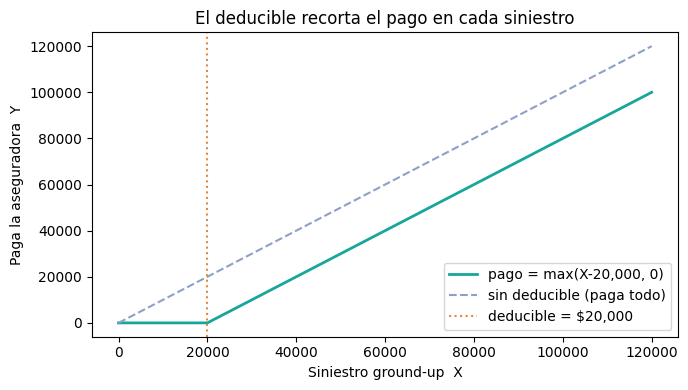

In [4]:
# ─── Visualizar la función de pago Y = max(X-d, 0) ─────────────────────────
d = 20_000
x = np.linspace(0, 120_000, 400)
plt.plot(x, np.maximum(x - d, 0), lw=2, color="#17A69B", label=f"pago = max(X-{d:,}, 0)")
plt.plot(x, x, ls="--", color="#8FA0C8", label="sin deducible (paga todo)")
plt.axvline(d, color="#E8873C", ls=":", label=f"deducible = ${d:,}")
plt.xlabel("Siniestro ground-up  X"); plt.ylabel("Paga la aseguradora  Y")
plt.legend(); plt.title("El deducible recorta el pago en cada siniestro")
plt.tight_layout(); plt.show()

---
<a id='4'></a>
## 4. Costo por siniestro vs. costo por pago

Un matiz que confunde y hay que tener claro. Hay **dos** esperanzas distintas:

- **Costo por siniestro (por pérdida):** $E[(X-d)_+]$ — promedia sobre **todos** los siniestros,
  incluidos los que caen por debajo del deducible y pagan 0. Es la que usamos para la prima
  (porque la frecuencia cuenta todos los siniestros).
- **Costo por pago:** $\dfrac{E[(X-d)_+]}{S(d)}$ — promedia **solo** sobre los siniestros que de hecho
  generan un pago ($X>d$). Es lo que la aseguradora desembolsa *cuando* paga.

Al subir $d$, el costo **por siniestro** siempre baja; pero el costo **por pago** primero baja y luego
**sube**, porque el deducible va "mordiendo" también siniestros grandes.

In [5]:
# ─── Las dos esperanzas, lado a lado ───────────────────────────────────────
def costo_por_pago(X, d):
    pagan = X > d
    return np.maximum(X - d, 0).sum() / pagan.sum() if pagan.sum() > 0 else np.nan

print(f"{'d':>8} | {'S(d)':>6} | {'costo/siniestro':>16} | {'costo/pago':>12}")
print("-" * 52)
for d in [0, 5_000, 10_000, 20_000, 30_000, 50_000]:
    Sd  = (X > d).mean()
    cps = E_deducible(X, d)
    cpp = costo_por_pago(X, d)
    print(f"${d:>7,} | {Sd:>6.3f} | ${cps:>14,.0f} | ${cpp:>11,.0f}")

       d |   S(d) |  costo/siniestro |   costo/pago
----------------------------------------------------
$      0 |  1.000 | $        52,463 | $     52,463
$  5,000 |  0.978 | $        47,493 | $     48,583
$ 10,000 |  0.899 | $        42,788 | $     47,596
$ 20,000 |  0.713 | $        34,750 | $     48,736
$ 30,000 |  0.547 | $        28,470 | $     52,039
$ 50,000 |  0.330 | $        19,908 | $     60,370


**¿Por qué el costo por pago hace "U"?** Hay dos fuerzas peleando al subir el deducible:

- **Hacia abajo:** a cada siniestro que paga le restas más (el deducible) → el pago promedio baja.
- **Hacia arriba:** dejas de pagar los siniestros chicos, así que los que *sí* sobreviven son cada vez los
  más caros → el promedio "de los que pagan" se jala hacia arriba.

Con deducible **chico** gana la primera (casi todos siguen cobrando, solo les quitas un poco → baja); con
deducible **grande** gana la segunda (solo sobreviven los gordos → sube). De ahí la **U**.

> **Ojo:** la U **no es universal**, depende de la distribución. En una **exponencial** el costo por pago
> es **constante** (por la falta de memoria). Aparece aquí porque la severidad real se parece a una
> **lognormal**. En lenguaje actuarial, el costo por pago es la **vida media residual** $e(d)=E[X-d\mid X>d]$.

### ✏️ Ejercicio 1 — tu curva de factores
Calcula el **factor de deducible** $E[(X-d)_+]/E[X]$ para una rejilla de deducibles pensada para tu ramo
(por ejemplo 0, 5 000, 10 000, …) y guárdalo en un DataFrame con columnas `deducible`, `factor`, `prima`.
Responde en una línea: ¿el factor baja de forma lineal o no? ¿por qué?

In [6]:
# Tu código aquí 👇


---
<a id='5'></a>
## 5. Coaseguro y límite (suma asegurada)

**Coaseguro** $c$ (convención mexicana): es la fracción del siniestro que queda **a cargo del asegurado**
después del deducible, así que la aseguradora paga $(1-c)$ de la parte indemnizable.

**Límite / suma asegurada** $M$: la aseguradora nunca paga más de $M$ por siniestro → $\min(X, M)$, con
$E[\min(X,M)] = \int_0^M S(x)\,dx$ (valor esperado limitado).

Juntando deducible, límite y coaseguro, el pago por siniestro es:

$$Y = (1-c)\,\big[\min(X, M) - \min(X, d)\big]$$

y la prima pura ajustada es $\text{frecuencia}\times E[Y]$.

In [7]:
# ─── Coaseguro: la aseguradora paga (1-c) ──────────────────────────────────
for c in [0.0, 0.10, 0.20, 0.30]:
    prima = freq * (1 - c) * EX
    print(f"coaseguro c = {c:>4.0%}  →  aseguradora paga {(1-c):.0%}  →  prima = ${prima:,.0f}")

print()
# ─── Todo junto: Y = (1-c)*(min(X,M) - min(X,d)) ───────────────────────────
d, M, c = 10_000, 400_000, 0.10
Y = (1 - c) * (np.minimum(X, M) - np.minimum(X, d))
print(f"Con d=${d:,}, M=${M:,}, c={c:.0%}:  E[Y] = ${Y.mean():,.0f}  →  prima = ${freq*Y.mean():,.0f}")

coaseguro c =   0%  →  aseguradora paga 100%  →  prima = $18,798
coaseguro c =  10%  →  aseguradora paga 90%  →  prima = $16,918
coaseguro c =  20%  →  aseguradora paga 80%  →  prima = $15,038
coaseguro c =  30%  →  aseguradora paga 70%  →  prima = $13,159

Con d=$10,000, M=$400,000, c=10%:  E[Y] = $37,781  →  prima = $13,537


**¿Por qué el coaseguro sí mueve la prima en proporción directa, y el deducible no?**

El coaseguro **multiplica**: es un porcentaje parejo sobre *todo*. Si el asegurado se queda con el 10% de
**cada peso**, la aseguradora paga el 90% de todo, sin importar el tamaño del siniestro → la prima entera
se multiplica por 0.90. Por eso es lineal y **no depende de la distribución**.

El deducible **resta**: recorta un pedazo fijo por abajo. Ese pedazo se come *enterito* a un siniestro
chico pero apenas raspa a uno grande → pega distinto a cada tamaño y por eso **depende de cómo esté
repartida la severidad** (es no lineal). En una frase: **el coaseguro multiplica, el deducible resta.**

---
<a id='6'></a>
## 6. Franquicia

La **franquicia** $f$ es un **umbral**, no una resta. Es *todo o nada*:

$$Y = X\cdot\mathbf{1}\{X > f\}$$

Si el siniestro no supera $f$, la aseguradora **no paga nada**; si lo supera, paga el **siniestro
completo** (no solo el exceso). Por eso, al mismo umbral, una franquicia paga **más** que un deducible.

> **En México:** el término dominante en ramos masivos (autos, GMM, daños) es *deducible*. La franquicia
> como umbral todo-o-nada aparece sobre todo en **transportes/marítimo**, algo de **responsabilidad civil**
> y en **reaseguro**. A veces se le llama "franquicia absoluta" al deducible y "franquicia simple" a este
> umbral — conviene aclararlo para no confundir.

In [8]:
# ─── Franquicia vs deducible al mismo umbral ───────────────────────────────
def E_franquicia(X, f):
    return (X * (X > f)).mean()          # E[X·1{X>f}]

print(f"{'umbral':>8} | {'deducible: prima':>18} | {'franquicia: prima':>18}")
print("-" * 52)
for u in [10_000, 20_000, 30_000]:
    pd_ded = freq * E_deducible(X, u)
    pd_fr  = freq * E_franquicia(X, u)
    print(f"${u:>7,} | ${pd_ded:>16,.0f} | ${pd_fr:>16,.0f}")

  umbral |   deducible: prima |  franquicia: prima
----------------------------------------------------
$ 10,000 | $          15,331 | $          18,553
$ 20,000 | $          12,451 | $          17,561
$ 30,000 | $          10,201 | $          16,082


### ✏️ Ejercicio 2 — deducible vs. franquicia
Para un umbral fijo (p. ej. $20,000) de tu ramo, calcula la prima bajo **deducible** y bajo **franquicia**.
¿Cuánto más paga la aseguradora con franquicia? Explica en una línea *por qué* una franquicia es más cara
que un deducible al mismo umbral.

In [9]:
# Tu código aquí 👇


---
<a id='7'></a>
## 7. Casos analíticos: exponencial y lognormal

Hay **dos formas** de calcular el mismo factor:

- **Empírico:** directo de los datos de la cartera, **sin suponer nada**. Promedias `max(X-d,0)` sobre los
  siniestros reales. Es *lo que dicen tus datos*.
- **Analítico:** **supones** que la severidad sigue una distribución conocida, le estimas los parámetros
  con los mismos datos, y usas su **fórmula** — ya no vuelves a tocar los datos crudos. Los parámetros:
  exponencial → $\theta = $ media de $X$; lognormal → $\mu,\sigma = $ media y desviación de $\ln X$.

Los tres números de la tabla de abajo (empírico, exponencial, lognormal) son **el mismo factor** calculado
de tres maneras. ¿Para qué el analítico si ya tengo el empírico? Para **extrapolar** a deducibles sin datos,
quitar el ruido de la muestra y escribir una nota técnica limpia ("supongo severidad lognormal con $\mu,\sigma$").

Dos casos clásicos:

**Exponencial** $X\sim\text{Exp}(\theta)$ (media $\theta$):
$$E[(X-d)_+] = \theta\,e^{-d/\theta}, \qquad \text{factor}(d) = e^{-d/\theta}$$
El factor es exactamente la supervivencia: elegante y fácil de explicar.

**Lognormal** $X\sim\text{Lognormal}(\mu,\sigma)$ (la que mejor describe la severidad real, sesgada):
$$E[X\wedge d] = e^{\mu+\sigma^2/2}\,\Phi\!\Big(\tfrac{\ln d-\mu-\sigma^2}{\sigma}\Big) + d\,\Big[1-\Phi\!\Big(\tfrac{\ln d-\mu}{\sigma}\Big)\Big],\qquad E[(X-d)_+] = E[X]-E[X\wedge d]$$

In [10]:
# ─── Ajustamos los dos modelos a NUESTRA severidad ─────────────────────────
theta = EX                                  # exponencial: media
mu, sigma = np.log(X).mean(), np.log(X).std()   # lognormal: en escala log
EX_ln = np.exp(mu + sigma**2 / 2)
print(f"Exponencial: theta = ${theta:,.0f}")
print(f"Lognormal  : mu = {mu:.4f}, sigma = {sigma:.4f}  →  E[X] = ${EX_ln:,.0f}")

def factor_exp(d):      return np.exp(-d / theta)
def Elim_lognormal(M):  # E[X ∧ M]
    return (EX_ln * norm.cdf((np.log(M) - mu - sigma**2) / sigma)
            + M * (1 - norm.cdf((np.log(M) - mu) / sigma)))
def factor_ln(d):       return (EX_ln - Elim_lognormal(d)) / EX_ln

print()
print(f"{'d':>8} | {'empírico':>9} | {'exponencial':>12} | {'lognormal':>10}")
print("-" * 48)
for d in [10_000, 20_000, 30_000]:
    fe = E_deducible(X, d) / EX
    print(f"${d:>7,} | {fe:>9.3f} | {factor_exp(d):>12.3f} | {factor_ln(d):>10.3f}")

Exponencial: theta = $52,463
Lognormal  : mu = 10.4165, sigma = 0.9466  →  E[X] = $52,286

       d |  empírico |  exponencial |  lognormal
------------------------------------------------
$ 10,000 |     0.816 |        0.826 |      0.815
$ 20,000 |     0.662 |        0.683 |      0.662
$ 30,000 |     0.543 |        0.564 |      0.543


Fíjate: la **lognormal ajustada reproduce casi exactamente** la curva empírica de factores — porque es
la distribución que de verdad describe esta severidad. La exponencial queda razonable pero menos fina.
Ese es el valor de modelar: una fórmula cerrada que *reemplaza* la tabla empírica y permite extrapolar.

---
<a id='8'></a>
## 8. La curva prima vs. deducible y las tablas de factores

Juntamos todo en una gráfica: cómo cae la prima al subir el deducible. La curva es **decreciente y
convexa** — no lineal. Y la **tabla de factores** que publican las aseguradoras es, literalmente, esta
curva tabulada: el *descuento* por deducible es el **resultado** de la distribución, no un número inventado.

/tmp/ipykernel_441/274186690.py:10: RuntimeWarning: divide by zero encountered in log
  return (EX_ln * norm.cdf((np.log(M) - mu - sigma**2) / sigma)
/tmp/ipykernel_441/274186690.py:11: RuntimeWarning: divide by zero encountered in log
  + M * (1 - norm.cdf((np.log(M) - mu) / sigma)))


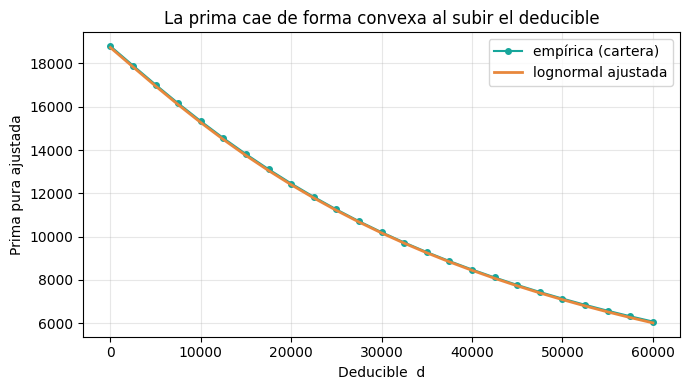

 deducible  factor   prima
         0   1.000 18798.0
      5000   0.905 17017.0
     10000   0.816 15331.0
     15000   0.735 13808.0
     20000   0.662 12451.0
     30000   0.543 10201.0


In [11]:
# ─── La curva prima vs deducible (empírica + lognormal) ────────────────────
ds = np.linspace(0, 60_000, 25)
primas_emp = [freq * E_deducible(X, d) for d in ds]
primas_ln  = [freq * EX_ln * factor_ln(d) for d in ds]

plt.plot(ds, primas_emp, "o-", color="#17A69B", ms=4, label="empírica (cartera)")
plt.plot(ds, primas_ln,  "-", color="#E8873C", lw=2, label="lognormal ajustada")
plt.xlabel("Deducible  d"); plt.ylabel("Prima pura ajustada")
plt.title("La prima cae de forma convexa al subir el deducible")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# La "tabla de factores" tabulada
tabla_factores = pd.DataFrame({
    "deducible": [0, 5_000, 10_000, 15_000, 20_000, 30_000],
})
tabla_factores["factor"] = tabla_factores["deducible"].apply(lambda d: E_deducible(X, d) / EX).round(3)
tabla_factores["prima"]  = (freq * tabla_factores["deducible"].apply(lambda d: E_deducible(X, d))).round(0)
print(tabla_factores.to_string(index=False))

---
<a id='9'></a>
## 9. El entregable: `prima_ajustada(...)`

Este es el **contrato de entrega** de la Práctica 2. Tu equipo debe producir **exactamente** esta función
para su ramo: recibe las condiciones de la póliza y devuelve la prima pura ajustada. La revisión la
evalúa con varios perfiles, así que respeta la firma y el significado de los argumentos.

In [12]:
# ─── CONTRATO DE ENTREGA ───────────────────────────────────────────────────
def prima_ajustada(deducible=0.0, coaseguro=0.0, limite=np.inf, X=X, freq=freq):
    """
    Prima pura ajustada por condiciones de cobertura.
      deducible : monto que absorbe el asegurado en cada siniestro  (>= 0)
      coaseguro : fracción a cargo del asegurado tras el deducible   (0 a 1)
      limite    : suma asegurada / pago máximo por siniestro         (> deducible)
    Devuelve: prima pura (por año-póliza) = frecuencia × E[pago].
    """
    pago = (1 - coaseguro) * (np.minimum(X, limite) - np.minimum(X, deducible))
    pago = np.maximum(pago, 0.0)
    return freq * pago.mean()

# Comprobación: sin condiciones debe dar la prima base
print(f"Sin condiciones      : ${prima_ajustada():,.2f}   (≈ prima pura base ${prima_pura_base:,.2f})")
print(f"d=10k                : ${prima_ajustada(deducible=10_000):,.2f}")
print(f"d=10k, c=10%, M=400k : ${prima_ajustada(deducible=10_000, coaseguro=0.10, limite=400_000):,.2f}")

Sin condiciones      : $18,797.89   (≈ prima pura base $18,797.89)
d=10k                : $15,331.38
d=10k, c=10%, M=400k : $13,537.30


### ✏️ Ejercicio 3 — el efecto del coaseguro
Usa `prima_ajustada` para calcular la prima de tu ramo con coaseguro de 0%, 10%, 20% y 30%
(deducible fijo). ¿El efecto del coaseguro sobre la prima es lineal? Compáralo con el del deducible.

In [13]:
# Tu código aquí 👇


### ✏️ Ejercicio 4 — tu tarifa de condiciones
Arma para tu ramo una **tabla de prima ajustada** combinando 3 deducibles × 2 niveles de coaseguro
usando `prima_ajustada`. Esta tabla es la semilla de tu cotizador (Práctica 2). Interprétala en 2–3 líneas.

In [14]:
# Tu código aquí 👇


---
<a id='10'></a>
## 10. Cierre

- El deducible, el coaseguro, el límite y la franquicia son **transformaciones de la severidad**: cambian
  $E[\text{pago}]$ y por eso re-precian la prima pura.
- Cuánto baja la prima **lo dicta la distribución** (la curva es convexa, no lineal). Las **tablas de
  factores** de las aseguradoras son esa curva tabulada — un *output*, no un supuesto.
- La **lognormal** describe bien la severidad real y da fórmula cerrada para extrapolar.
- Te llevas una función, `prima_ajustada(...)`, que es el **entregable** de la Práctica 2 y el corazón del
  cotizador que construiremos en las Sesiones 13–14.

**Próxima sesión:** de dónde salen los recargos (gastos, comisiones, margen) leyendo los estados de
resultados del sector — la guía de ramos.